# Gluing two nets, and rates from parameters

Two questions that come up once a Petri net is written in pieces. The first is
composition: a net `A → TAB → B → TBC → C` written as two nets, `netAB` and `netBC`, that
share the place `B`. What does composing the two give, and what does it take to get the
net that was meant? The second is rates: an SIR net whose infection rate is a function of
parameters, and in one version of the recovered count too, when a rate in SPN is a
number. Both are answered with `zrth.petri`: a rate scaled by a token count or by a real
input, and an arc as the interface of a net.

In [ ]:
import matplotlib.pyplot as plt

from zrth import LIA, SPN, Bool, Clock, Int, Real, Var
from zrth import Module as compose
from zrth.eval import execute_init, execute_update
from zrth.petri import TIME, Arc, Place, Transition
from zrth.simulate import simulate
from zrth.sugar import Module, X, d, ite

## Two nets sharing a place, composed

The two nets first as untimed nets in LIA, written by hand: a transition fires in every
round in which its source holds a token, and a place adds or removes a token in the round
the transition fires. Each net is a function declaring its own variables, `B` among them,
as two files would.

In [ ]:
INT, BOOL = Int([1, 1]), Bool([1, 1])


def net_ab(a0=3, b0=1):
    A, B, fire_TAB = Var(INT), Var(INT), Var(BOOL)

    class Transition_TAB(Module):
        def init(self, src):
            return False

        def next(self, fire, src):
            return src > 0

    class Place_A(Module):
        def init(self, fire_TAB):
            return a0

        def next(self, a, fire_TAB):
            return ite(X(fire_TAB), a - 1, a)

    class Place_B(Module):
        def init(self, fire_TAB):
            return b0

        def next(self, b, fire_TAB):
            return ite(X(fire_TAB), b + 1, b)

    net = compose(
        Transition_TAB(theory=LIA, ctrl=(fire_TAB,), extl=(A,)),
        Place_A(theory=LIA, ctrl=(A,), extl=(fire_TAB,)),
        Place_B(theory=LIA, ctrl=(B,), extl=(fire_TAB,)),
    )
    return net, A, B


def net_bc(b0=1, c0=0):
    B, C, fire_TBC = Var(INT), Var(INT), Var(BOOL)

    class Transition_TBC(Module):
        def init(self, src):
            return False

        def next(self, fire, src):
            return src > 0

    class Place_B(Module):
        def init(self, fire_TBC):
            return b0

        def next(self, b, fire_TBC):
            return ite(X(fire_TBC), b - 1, b)

    class Place_C(Module):
        def init(self, fire_TBC):
            return c0

        def next(self, c, fire_TBC):
            return ite(X(fire_TBC), c + 1, c)

    net = compose(
        Transition_TBC(theory=LIA, ctrl=(fire_TBC,), extl=(B,)),
        Place_B(theory=LIA, ctrl=(B,), extl=(fire_TBC,)),
        Place_C(theory=LIA, ctrl=(C,), extl=(fire_TBC,)),
    )
    return net, B, C

An untimed net is stepped with the discrete interpreter, one round per step: every atom
writes its next wires, then the values are latched.

In [ ]:
def rounds(net, columns, n):
    state = {}
    execute_init(state, net.atoms)
    table = []
    for _ in range(n + 1):
        for v in net.ctrl:
            state[v] = state[X(v)]
        table.append([int(state[v]) for v in columns.values()])
        execute_update(state, net.atoms)
    print("round  " + "  ".join(f"{name:>6}" for name in columns))
    for k, row in enumerate(table):
        print(f"{k:>5}  " + "  ".join(f"{x:>6}" for x in row))


netAB, A, B_ab = net_ab()
netBC, B_bc, C = net_bc()
netABC = compose(netAB, netBC)

print("netABC controls", len(netABC.ctrl), "variables; the two B are one variable:", B_ab == B_bc)
rounds(netABC, {"A": A, "B(AB)": B_ab, "B(BC)": B_bc, "C": C}, 5)

netABC controls 6 variables; the two B are one variable: False
round       A   B(AB)   B(BC)       C
    0       3       1       1       0
    1       2       2       0       1
    2       1       3       0       1
    3       0       4       0       1
    4       0       4       0       1
    5       0       4       0       1


The composition succeeds, and there are two places `B`. A `Var` is an identity, not a
name: `Var(INT)` in one net and `Var(INT)` in the other are two variables, and composition
has nothing to glue. `TAB` drains `A` into one `B`; `TBC` takes the single initial token of
the other `B` and stops. Had the two nets shared one `Var`, the composition would have
been refused instead, since two modules would control it: a variable has one controller.
Either way, two closed nets do not compose into the net that was meant.

Why the composition goes through: a module is a set of atoms, one per `sugar.Module`,
each controlling some variables and reading others. Composing is taking the union of the
atoms, under two checks: no variable controlled twice, no circular wait within a round.
Nothing requires a connection. Atoms are connected where one reads a variable another
controls, and that takes the same `Var` object on both sides. Here the six atoms form two
clusters with no variable crossing between them, and both checks pass trivially: the two
nets run side by side, one module, not joined.

## Gluing planned: an open arc

In `zrth.petri` the interface of a net is the arc. An `Arc` carries the two variables
between a transition and a place: the event the transition toggles when it fires, and,
for an arc from a place to a transition, the Bool the place keeps equal to "there are
tokens for it". A place owns its count and writes the Bool of each outgoing arc; a
transition owns its clock and toggles the event of each of its arcs. Gluing two nets is
then sharing an arc: `netAB` keeps the place `B` and gives it an outgoing arc with no
transition behind it, `netBC` gives that same arc to `TBC` as its input and has no place
`B`. Composition fills the arc. The two transitions have rate 1 here; the untimed net
above fires whenever it can.

In [ ]:
def petri_ab(a0=3, b0=1):
    a_out, b_in, b_out = Arc("consumption"), Arc("production"), Arc("consumption")
    TAB = Transition(1.0, inputs=[a_out], outputs=[b_in], name="TAB")
    A = Place(a0, outputs=[a_out], name="A")
    B = Place(b0, inputs=[b_in], outputs=[b_out], name="B")
    return compose(TAB, A, B), A, B, b_out


def petri_bc(b_out, c0=0):
    c_in = Arc("production")
    TBC = Transition(1.0, inputs=[b_out], outputs=[c_in], name="TBC")
    C = Place(c0, inputs=[c_in], name="C")
    return compose(TBC, C), C


netAB, A, B, b_out = petri_ab()
netBC, C = petri_bc(b_out)
netABC = compose(netAB, netBC)

print("netAB reads: ", netAB.extl)
print("netBC reads: ", netBC.extl)
print("netABC reads:", netABC.extl)

netAB reads:  [{#0 : Clock { rank: 0 }}, {#52 : Event}]
netBC reads:  [{#0 : Clock { rank: 0 }}, {#55 : Bool([1, 1])}]
netABC reads: [{#0 : Clock { rank: 0 }}]


Each open net reads one half of the arc besides the time reference: `netAB` the event
`TBC` toggles when it takes a token, `netBC` the Bool `B` writes when it has one. The
closed net reads the time reference alone.

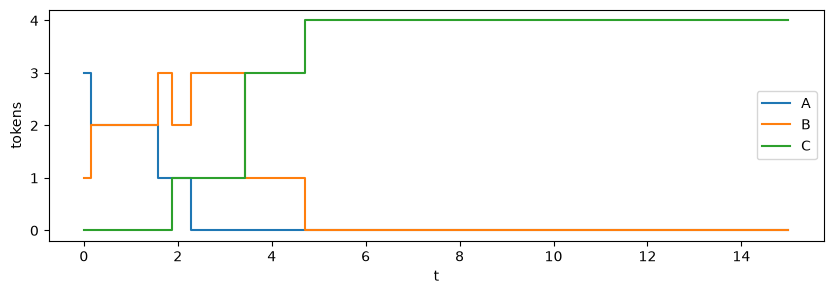

In [ ]:
planned = simulate(netABC, horizon=15.0, seed=1)
planned_places = (A, B, C)

fig, ax = plt.subplots(figsize=(10, 3))
for place in (A, B, C):
    ax.step(planned.times, planned.series(place.count), where="post", label=place.name)
ax.set_xlabel("t")
ax.set_ylabel("tokens")
ax.legend()
plt.show()

An open arc is also how a transition is controlled: whatever writes its Bool decides
whether the transition may fire. `netBC` on its own runs with a policy standing in for the
missing place, here one that always offers a token.

In [ ]:
def always_offered(time, state):
    return {b_out.enabled: True}


alone = simulate(netBC, horizon=5.0, seed=1, policy=always_offered)
print("netBC alone, always offered a token: C holds", alone.series(C.count)[-1], "tokens at t = 5")

netBC alone, always offered a token: C holds 5 tokens at t = 5


## Gluing after the fact: a rebuild

The nets were not written to be composed: each is closed, with a `B` of its own. No
composition of the two closed modules gives the net, for the reason above. What gives it
is a rebuild from the parts, which the `zrth.petri` objects keep: a place knows its arcs,
an arc knows its transition. The two places `B` are dropped and one is built with the
union of their arcs; it takes over the Bool of every arc the old places wrote. The
transitions and the other places are composed again as they are.

The rebuild has to make two decisions the nets do not. The initial marking of the new
`B`, which the two nets may give differently; here it is an argument. And the order in
which `TAB` and `TBC` are served in a round where both fire, which is the order of the
new place's `outputs`.

In [ ]:
def closed_ab(a0=3, b0=1):
    a_out, b_in = Arc("consumption"), Arc("production")
    TAB = Transition(1.0, inputs=[a_out], outputs=[b_in], name="TAB")
    A = Place(a0, outputs=[a_out], name="A")
    B = Place(b0, inputs=[b_in], name="B")
    return TAB, A, B


def closed_bc(b0=1, c0=0):
    b_out, c_in = Arc("consumption"), Arc("production")
    TBC = Transition(1.0, inputs=[b_out], outputs=[c_in], name="TBC")
    B = Place(b0, outputs=[b_out], name="B")
    C = Place(c0, inputs=[c_in], name="C")
    return TBC, B, C


def fused(initial, *places):
    inputs = [arc for place in places for arc in place.inputs]
    outputs = [arc for place in places for arc in place.outputs]
    return Place(initial, inputs=inputs, outputs=outputs, name=places[0].name)


TAB, A, B_ab = closed_ab()
TBC, B_bc, C = closed_bc()
netAB, netBC = compose(TAB, A, B_ab), compose(TBC, B_bc, C)

B = fused(1, B_ab, B_bc)
rebuilt = compose(compose(TAB, A, B), compose(TBC, C))

trace = simulate(rebuilt, horizon=15.0, seed=1)
same = trace.times == planned.times and all(
    trace.series(p.count) == planned.series(q.count) for p, q in zip((A, B, C), planned_places)
)
print("the rebuilt net runs as the planned one:", same)

the rebuilt net runs as the planned one: True


The rebuilt net is the planned one: the same modules, composed in the same order, so the
same run from the same seed. The difference is where the decisions were made. Planned,
the open arc stood for "someone may take tokens from `B`" from the start, and whatever
`netAB` guarantees on its own holds in the composition. Rebuilt, `B` is a new place and
what held of `netAB` alone, that `B` never decreases for one, has to be checked again.

## SIR: a rate from parameters

A population of a hundred, each person in one of three places: susceptible `S`, infected
`I`, recovered `R`. Two transitions: `infect` moves one person from `S` to `I`, firing at a
rate λ while both places are non-empty; `recover` moves one from `I` to `R` at a rate γ.
Both rates are plain numbers here that do not count the people in each place: this
infection is not the law of mass action, which would be `scale=[S, I]`.

The question is where λ comes from. In a first version it is computed from three
parameters: a base rate, an intervention level and how effective the intervention is. In
a second it also depends on the recovered count: the more recovered, the fewer follow the
intervention, so the rate creeps up. An SPN rate is a literal number, so neither can be
written as a formula inside the net. That is a limit of SPN, not of the framework: in the
coloured nets to come, where reals move and are multiplied, a rate is a term of the
colours and counts. Within SPN the two have answers of their own, below, and a third
part adds an objective: the average fraction infected over the run.

The net is built once, for a list of infection transitions, each given as its rate and
the factors scaling it, a place by name or a real input.

In [ ]:
S0, I0, R0 = 99, 1, 0
N = S0 + I0 + R0
BETA0, EFFICACY, INTERVENTION = 0.4, 0.8, 0.5
GAMMA = 0.1


def sir(infections=()):
    s_out, i_en, i_in = [], [], []
    for _ in infections:
        s_out.append(Arc("consumption"))
        i_en.append(Arc("enabling"))
        i_in.append(Arc("production"))
    i_out, r_in = Arc("consumption"), Arc("production")
    S = Place(S0, outputs=s_out, name="S")
    I = Place(I0, inputs=i_in, outputs=[*i_en, i_out], name="I")
    R = Place(R0, inputs=[r_in], name="R")
    places = {"S": S, "I": I, "R": R}
    infect = [
        Transition(
            rate,
            inputs=[s, en],
            outputs=[prod],
            scale=[places[f] if isinstance(f, str) else f for f in scale],
            name="infect",
        )
        for (rate, scale), s, en, prod in zip(infections, s_out, i_en, i_in)
    ]
    recover = Transition(GAMMA, inputs=[i_out], outputs=[r_in], name="recover")
    return compose(*infect, recover, S, I, R), S, I, R

### A static rate: λ(θ) = β₀ (1 − efficacy · intervention)

The natural first attempt is a constant module holding the parameters, a second module
multiplying them into λ, and the transition armed with `exp(lam)`. None of that is in
the theory: `Exp` takes a literal, LRA has no product of two variables, and a net runs on
one theory. Two things are. λ(θ) is a number, so it is the rate. And a rate can be scaled
by a real input: a `Var(Real([1, 1]))` in `scale=` multiplies the rate by whatever drives
it, here a policy holding the factor `1 − efficacy · intervention`. The two give the same
run, to rounding.

In [ ]:
LAMBDA = BETA0 * (1 - EFFICACY * INTERVENTION)
factor = Var(Real([1, 1]))

literal, *_ = sir([(LAMBDA, [])])
scaled, *_ = sir([(BETA0, [factor])])


def intervention_factor(time, state):
    return {factor: 1 - EFFICACY * INTERVENTION}


t1 = simulate(literal, horizon=200.0, seed=0)
t2 = simulate(scaled, horizon=200.0, seed=0, policy=intervention_factor)
print(f"{len(t1)} rounds each; the firing times differ by at most {max(abs(a - b) for a, b in zip(t1.times, t2.times)):.1e}")

52 rounds each; the firing times differ by at most 5.7e-14


### A marking-dependent rate: λ(θ, R) = β₀ (1 − efficacy · intervention · (1 − R / N))

The second attempt makes λ a function of the recovered count and re-arms the clock
whenever `R` changes. Re-arming an exponential clock is sound, it is memoryless, but the
formula is not an SPN term. It is affine in `R`:

λ(θ, R) = a + b R, with a = β₀ (1 − efficacy · intervention) and b = β₀ · efficacy · intervention / N.

Two Poisson streams add to one, so an infection at rate a + b R is two transitions with
the same arcs: one at rate a, one at rate b scaled by the count of `R`. The second runs
`b · R` times as fast as its clock says and stands still while `R` is empty. No clock is
re-armed, and the marking is exactly the chain the formula describes.

In [ ]:
a = BETA0 * (1 - EFFICACY * INTERVENTION)
b = BETA0 * EFFICACY * INTERVENTION / N
dynamic, S, I, R = sir([(a, []), (b, ["R"])])

trace = simulate(dynamic, horizon=300.0, seed=3)

fig, ax = plt.subplots(figsize=(10, 3))
for place in (S, I, R):
    ax.step(trace.times, trace.series(place.count), where="post", label=place.name)
ax.set_xlabel("t")
ax.set_ylabel("tokens")
ax.legend()
plt.show()

### Time averages as flows

Two objectives on the side, both averages of the prevalence `I / N`. The time average
over the run, `(1 / T) ∫₀ᵀ I / N dt`, is a clock that integrates the prevalence, scaled so
that its value at the horizon `T` is the average. The rolling average over a window of
length `W` is the mean of the prevalence over the last complete window: a clock counts
the window down, a second one accumulates the prevalence over it, and at the window's
end the accumulated mean is published and the accumulator starts again, so the published
value changes once per window and is 0 before the first ends.

Both flows have a count in them, `(I / N) · d(t)`. Without a count scaling a flow, that
has to be spelt out as a chain of a hundred constant cases, one per value of `I`; with
it each flow is one line.

In [ ]:
HORIZON, WINDOW = 300.0, 32.0
average = Var(Clock())
window, total, rolling = Var(Clock()), Var(Clock()), Var(Clock())


class TimeAverage(Module):
    def init(self, i, t):
        return 0.0

    def next(self, average, i, t):
        return average

    def flow(self, average, i, t):
        return i * ((1 / (N * HORIZON)) * d(t))


class WindowAverage(Module):
    def init(self, i, t):
        return WINDOW, 0.0, 0.0

    def next(self, window, total, rolling, i, t):
        ends = window == 0
        return ite(ends, WINDOW, window), ite(ends, 0.0, total), ite(ends, total, rolling)

    def flow(self, window, total, rolling, i, t):
        return ite(window >= 0, -1 * d(t), None), i * ((1 / (N * WINDOW)) * d(t)), 0


dynamic, S, I, R = sir([(a, []), (b, ["R"])])
objectives = compose(
    TimeAverage(theory=SPN, ctrl=(average,), extl=(I.count, TIME)),
    WindowAverage(theory=SPN, ctrl=(window, total, rolling), extl=(I.count, TIME), hide={window, total}),
)
trace = simulate(compose(dynamic, objectives), horizon=HORIZON, seed=3)


def prevalence_integral(trace, start, end):
    area = 0.0
    for (now, state), later in zip(trace, trace.times[1:]):
        overlap = min(later, end) - max(now, start)
        if overlap > 0:
            area += state[I.count] * overlap
    return area / N


last = WINDOW * (HORIZON // WINDOW)
print(f"time average:    module {trace.series(average)[-1]:.6f}, from the trace {prevalence_integral(trace, 0, HORIZON) / HORIZON:.6f}")
print(f"rolling average: module {trace.series(rolling)[-1]:.6f}, from the trace {prevalence_integral(trace, last - WINDOW, last) / WINDOW:.6f}")

time average:    module 0.295716, from the trace 0.295716
rolling average: module 0.575116, from the trace 0.575116


## Beyond this: an intervention problem

The same net with an intervention is the problem of the RL tutorial: a policy `u = π(R)`,
an infection rate `β₀ (1 − efficacy · u)`, a time-average cost
`(1 / T) ∫ (I / N + c · u) dt` and a monitor for `(I ≤ capacity) U (I = 0)`. It is made of
the same pieces. The policy is a module that outputs the factor `1 − efficacy · u` as a
real, scaling the infection's rate; the cost is two scaled flows, one for the integral of
`I`, one for the integral of `u`, added outside the net; the monitor's three states are an
`Enum(3)`, and the comparison with the capacity is `i > CAPACITY`.

Two things stay outside SPN. A rate given by an arbitrary formula of parameters and counts
inside the model, rather than a product of factors, and a flow that is the sum of two
terms: both belong to the coloured nets, where reals move and are multiplied. And an SPN
rate is a number, so parameters that a solver should range over are real inputs, driven
from outside the net, as `factor` above.